In [3]:
import ast
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import LabelEncoder

In [4]:
df = pd.read_pickle("data/df_train.pkl")
df_train, df_val = train_test_split(df, test_size=0.1, random_state=42)

In [5]:
def parse_embedding(val):
    if isinstance(val, str):
        return np.array(ast.literal_eval(val))
    return np.array(val)

X_train = np.array(
    [parse_embedding(x) for x in df_train.business_description_embedding]
)
X_val = np.array(
    [parse_embedding(x) for x in df_val.business_description_embedding]
)

In [ ]:
label_encoder = LabelEncoder()
y_train = label_encoder.fit_transform(df_train["industry"])
y_val = label_encoder.transform(df_val["industry"])

train_classes = set(y_train)
val_classes = set(y_val)
print(f"Number of classes in Train: {len(train_classes)}")
print(f"All classes in Val are in Train: {val_classes.issubset(train_classes)}")

Número de clases en Train: 25
Todas las clases de Val están en Train: True


/var/folders/56/fsf9s_y919n4q871y5f4kf500000gn/T/ipykernel_28192/3402845309.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=class_counts.values, y=class_counts.index, palette="viridis")


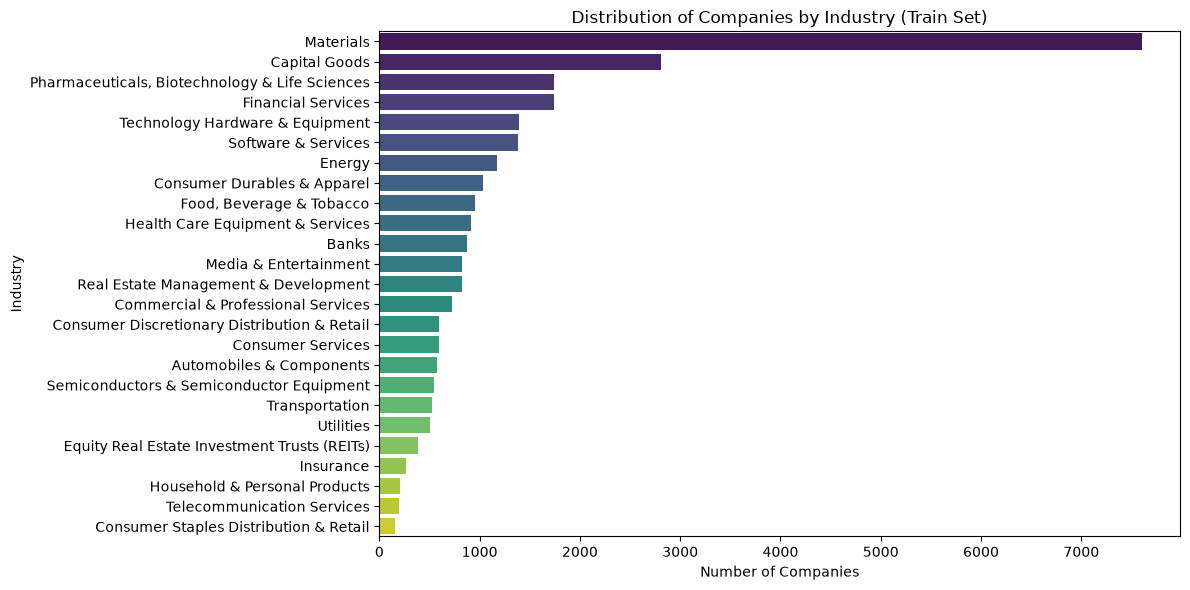

                                         Industry  Frequency  Percentage (%)
0                                       Materials       7604       26.647976
1                                   Capital Goods       2805        9.830033
2  Pharmaceuticals, Biotechnology & Life Sciences       1742        6.104784
3                              Financial Services       1740        6.097775
4                 Technology Hardware & Equipment       1390        4.871211
5                             Software & Services       1384        4.850184
6                                          Energy       1174        4.114246
7                     Consumer Durables & Apparel       1037        3.634134
8                        Food, Beverage & Tobacco        956        3.350272
9                Health Care Equipment & Services        911        3.192571


In [8]:
plt.figure(figsize=(12, 6))
class_counts = df_train["industry"].value_counts()
sns.barplot(x=class_counts.values, y=class_counts.index, palette="viridis")
plt.title("Distribution of Companies by Industry (Train Set)")
plt.xlabel("Number of Companies")
plt.ylabel("Industry")
plt.tight_layout()
plt.show()

# Tabla de resumen
df_class_dist = pd.DataFrame(
    {
        "Industry": class_counts.index,
        "Frequency": class_counts.values,
        "Percentage (%)": (class_counts.values / len(df_train)) * 100,
    }
)
print(df_class_dist.head(10))

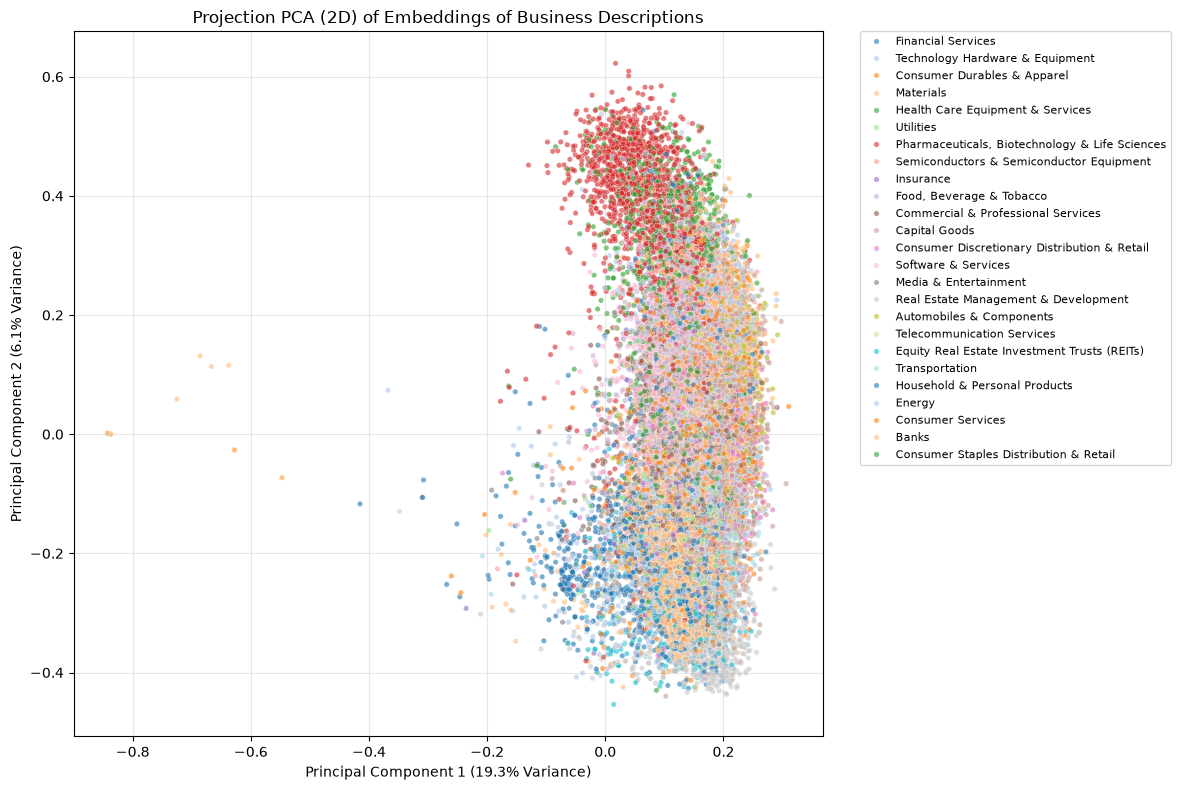

In [9]:
pca = PCA(n_components=2, random_state=42)
X_train_pca = pca.fit_transform(X_train)

# Scatter plot
plt.figure(figsize=(12, 8))
scatter = sns.scatterplot(
    x=X_train_pca[:, 0],
    y=X_train_pca[:, 1],
    hue=df_train["industry"],
    palette="tab20",
    alpha=0.6,
    s=15,
)
plt.title("Projection PCA (2D) of Embeddings of Business Descriptions")
plt.xlabel(
    f"Principal Component 1 ({pca.explained_variance_ratio_[0]:.1%} Variance)"
)
plt.ylabel(
    f"Principal Component 2 ({pca.explained_variance_ratio_[1]:.1%} Variance)"
)
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left", borderaxespad=0, fontsize=8)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# 1. Logistic Regression
lr_model = LogisticRegression(max_iter=1000, random_state=42, C=1.0)
lr_model.fit(X_train, y_train)
y_pred_lr = lr_model.predict(X_val)

# 2. k-Nearest Neighbors
knn_model = KNeighborsClassifier(n_neighbors=15, weights="distance", n_jobs=-1)
knn_model.fit(X_train, y_train)
y_pred_knn = knn_model.predict(X_val)

# 3. Metrics
acc_lr = accuracy_score(y_val, y_pred_lr)
f1_weighted_lr = f1_score(y_val, y_pred_lr, average="weighted")

acc_knn = accuracy_score(y_val, y_pred_knn)
f1_weighted_knn = f1_score(y_val, y_pred_knn, average="weighted")

# Comparison
results_df = pd.DataFrame(
    {
        "Model": ["Logistic Regression", "k-NN (k=15)"],
        "Accuracy": [acc_lr, acc_knn],
        "Weighted F1-Score": [f1_weighted_lr, f1_weighted_knn],
    }
)
print(results_df)

where does the model miss?

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# Confusion Matrix - Logistic Regression
cm_lr = confusion_matrix(y_val, y_pred_lr)
sns.heatmap(
    cm_lr,
    ax=axes[0],
    cmap="Blues",
    fmt="d",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_,
)
axes[0].set_title("Confusion Matrix: Logistic Regression")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")
axes[0].tick_params(axis="x", rotation=90)

# Confusion Matrix - k-NN
cm_knn = confusion_matrix(y_val, y_pred_knn)
sns.heatmap(
    cm_knn,
    ax=axes[1],
    cmap="Greens",
    fmt="d",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_,
)
axes[1].set_title("Confusion Matrix: k-NN")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")
axes[1].tick_params(axis="x", rotation=90)

plt.tight_layout()
plt.show()